# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [7]:
# 1. Scanner protocol: 512 x 512 x 300
# 16 bits = 2 bytes per voxel
n_voxels = 512 * 512 * 300
scan_mb = (n_voxels * 2) / (1024 * 1024)

# 2. Voxel size: 0.5 x 0.5 x 1.0 mm
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0) # (x, y, z)
voxel_mm3 = 0.5 * 0.5 * 1.0

# 3. Front-view frame: rays along y (512 steps), image size is x by z (512 * 300 rays)
samples_per_frame = (512 * 300) * 512
samples_video = samples_per_frame * 120

# 4. With 35% early ray termination average
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400




```markdown
**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_
1. **Geometric distortion (stretching):** The anatomy along the Z-axis would appear squashed or flattened by half because the voxel height (1.0 mm) is twice its width/depth (0.5 mm). If treated as isotropic (1:1 aspect ratio), the coronal and sagittal reconstructions would be severely distorted.
2. **Artifacts and aliasing (blurring):** Features along the slice selection direction (Z-axis) would suffer from lower resolution (stair-step artifacts or jagged edges) compared to the higher-resolution in-plane (X-Y) dimensions. Failing to reconstruct with correct aspect ratio resampling results in non-orthogonal aspect ratios and incorrect scaling measurements.
```

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

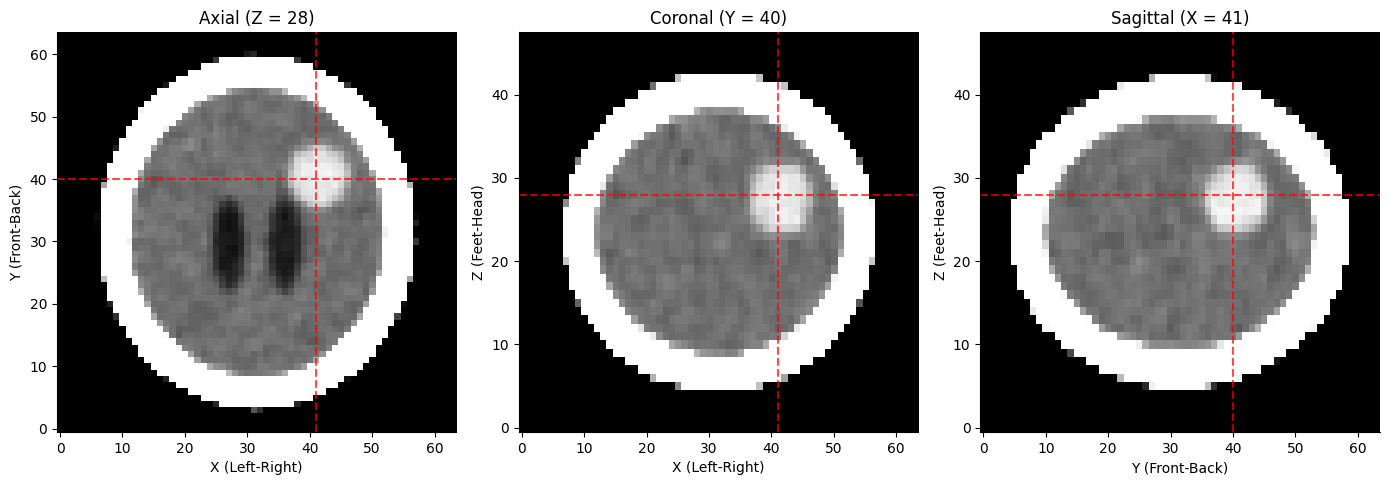

Detected centroid: (28, 40, 41)
Ground-truth centroid: (27.50, 40.50, 41.50)
Distance error: 2.92 mm


In [8]:
from scipy import ndimage

def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# 1. Brain masking and erosion to find candidate tumor voxels
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
eroded_inside = ndimage.binary_erosion(inside, iterations=3)
candidates = eroded_inside & (vol > 55) & (vol < 90)

# 2. Extract the largest connected component and its centroid
labeled, num_features = ndimage.label(candidates)
if num_features > 0:
    sizes = ndimage.sum(candidates, labeled, range(1, num_features + 1))
    largest_label = np.argmax(sizes) + 1
    lesion = (labeled == largest_label)
    cz, cy, cx = [int(round(c)) for c in ndimage.center_of_mass(lesion)]
else:
    lesion = np.zeros_like(vol, dtype=bool)
    cz, cy, cx = 0, 0, 0

# 3. Plot orthogonal slices through centroid
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial: x-y plane
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap='gray', origin='lower')
axes[0].axvline(cx, color='red', linestyle='--', alpha=0.7)
axes[0].axhline(cy, color='red', linestyle='--', alpha=0.7)
axes[0].set_title(f"Axial (Z = {cz})")
axes[0].set_xlabel("X (Left-Right)")
axes[0].set_ylabel("Y (Front-Back)")

# Coronal: x-z plane
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap='gray', origin='lower', aspect=ASPECT)
axes[1].axvline(cx, color='red', linestyle='--', alpha=0.7)
axes[1].axhline(cz, color='red', linestyle='--', alpha=0.7)
axes[1].set_title(f"Coronal (Y = {cy})")
axes[1].set_xlabel("X (Left-Right)")
axes[1].set_ylabel("Z (Feet-Head)")

# Sagittal: y-z plane
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap='gray', origin='lower', aspect=ASPECT)
axes[2].axvline(cy, color='red', linestyle='--', alpha=0.7)
axes[2].axhline(cz, color='red', linestyle='--', alpha=0.7)
axes[2].set_title(f"Sagittal (X = {cx})")
axes[2].set_xlabel("Y (Front-Back)")
axes[2].set_ylabel("Z (Feet-Head)")

plt.tight_layout()
plt.show()

# 4. Evaluation
gt_lesion = (labels == 5)
if np.any(gt_lesion):
    gt_z, gt_y, gt_x = ndimage.center_of_mass(gt_lesion)
    dist_mm = np.sqrt(((cz - gt_z)*SPACING[0])**2 + ((cy - gt_y)*SPACING[1])**2 + ((cx - gt_x)*SPACING[2])**2)
    print(f"Detected centroid: ({cz}, {cy}, {cx})")
    print(f"Ground-truth centroid: ({gt_z:.2f}, {gt_y:.2f}, {gt_x:.2f})")
    print(f"Distance error: {dist_mm:.2f} mm")
else:
    print("Ground truth lesion label 5 not found in labels volume!")

```markdown
**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
The partial-volume effect occurs because individual voxels at the boundary of different tissue types (like bone and brain) contain a mixture of both materials, resulting in intermediate Hounsfield Unit (HU) intensities. Since high-density bone (~1000 HU) and cerebrospinal fluid (CSF) or soft tissue have a wide boundary, their partial-volume voxels fall exactly in the 55–90 HU range. This creates a fake "shell" of intensities mimicking brain/tumour tissue directly beneath the skull. Performing binary erosion shrinks the brain mask away from this skull boundary, stripping away these false partial-volume artifact voxels so that we do not mistakenly segment them as the lesion.
```

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,Threshold,Voxels,Volume (mL),Dice Overlap
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


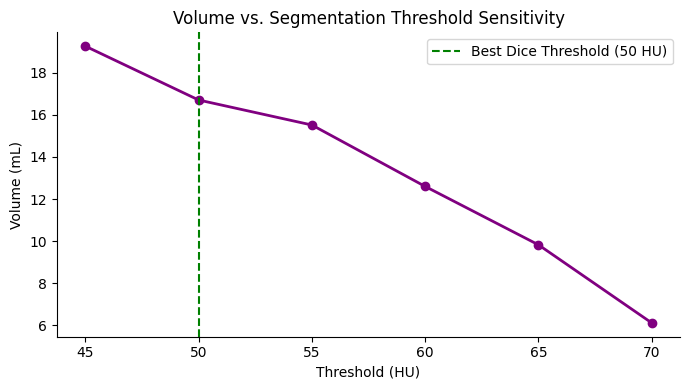

Volume Range to Report: 6.12 mL to 19.26 mL (Best Estimate: 16.70 mL)


In [9]:
truth = labels == 5
rows = []

# 1. Grow region and measure metrics for different thresholds
for c in [45, 50, 55, 60, 65, 70]:
    # Segment voxels above threshold
    thresh_mask = vol > c
    labeled_mask, num_feat = ndimage.label(thresh_mask)

    # Keep only the component that contains the tumor centroid (cz, cy, cx)
    if num_feat > 0:
        lesion_id = labeled_mask[cz, cy, cx]
        if lesion_id > 0:
            tumor_comp = (labeled_mask == lesion_id)
        else:
            # fallback to closest/largest overlap if centroid is missed
            tumor_comp = np.zeros_like(vol, dtype=bool)
    else:
        tumor_comp = np.zeros_like(vol, dtype=bool)

    v_count = np.sum(tumor_comp)
    vol_ml = v_count * VOXEL_MM3 / 1000.0

    # Calculate Dice coefficient with truth
    intersection = np.sum(tumor_comp & truth)
    dice = (2.0 * intersection) / (np.sum(tumor_comp) + np.sum(truth)) if (np.sum(tumor_comp) + np.sum(truth)) > 0 else 0.0

    rows.append({"Threshold": c, "Voxels": v_count, "Volume (mL)": vol_ml, "Dice Overlap": dice})

table = pd.DataFrame(rows)
display(table)

# 3. Plot volume vs threshold
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["Threshold"], table["Volume (mL)"], marker='o', color='purple', linewidth=2)
ax.set_title("Volume vs. Segmentation Threshold Sensitivity")
ax.set_xlabel("Threshold (HU)")
ax.set_ylabel("Volume (mL)")

best_idx = table["Dice Overlap"].idxmax()
best_thresh = table.loc[best_idx, "Threshold"]
best_vol = table.loc[best_idx, "Volume (mL)"]
ax.axvline(best_thresh, color='green', linestyle='--', label=f'Best Dice Threshold ({best_thresh} HU)')
ax.legend()
plt.tight_layout()
plt.show()

# 4. Range report
min_vol = table["Volume (mL)"].min()
max_vol = table["Volume (mL)"].max()
print(f"Volume Range to Report: {min_vol:.2f} mL to {max_vol:.2f} mL (Best Estimate: {best_vol:.2f} mL)")

```markdown
**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_
To choose and justify $c$, I would use a sensitivity analysis of Hounsfield Unit profiles across the tumor-to-brain tissue boundary and select a threshold corresponding to the inflection point of the intensity gradient. To visualize this uncertainty, instead of showing a single hard boundary, I would present the surgeon with a probability map or a multi-colored overlay displaying multiple contours (e.g., nesting the volume boundaries of 50 HU, 55 HU, and 60 HU). This clearly depicts the "fuzzy" boundary region where partial-volume effects dominate, visually communicating the spatial variation and volumetric uncertainty.
```

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

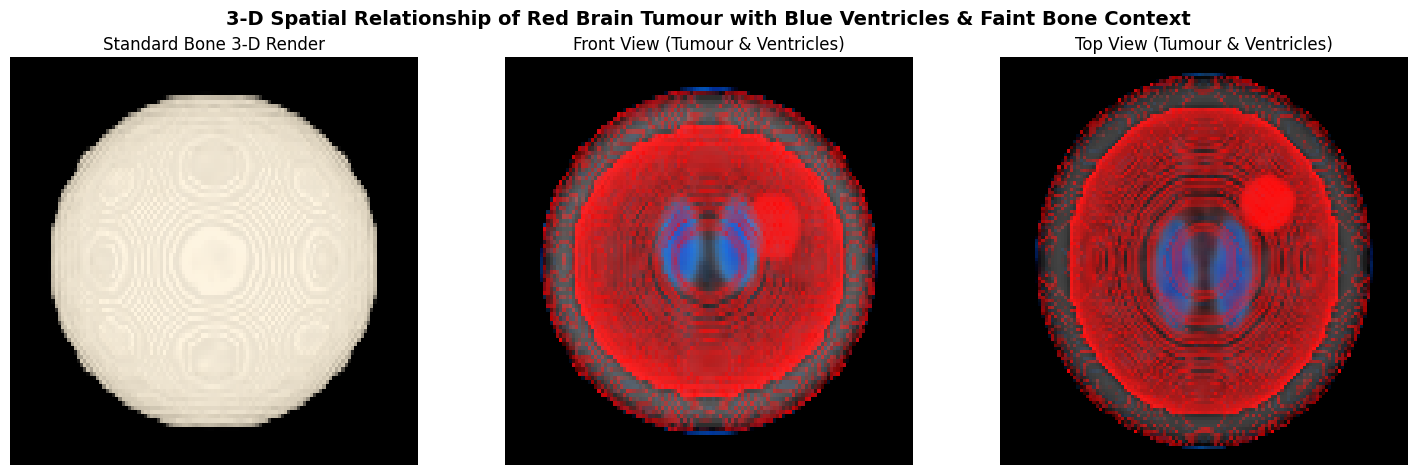

In [10]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# 2. Designed transfer function to highlight tumor (red) and ventricles/CSF (blue)
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0),
    (0, (0, 0, 1), 0.0),      # CSF start (transparent blue)
    (15, (0, 0.5, 1), 0.08),  # CSF/Ventricles
    (35, (0.5, 0.5, 0.5), 0), # Brain tissue background
    (55, (1, 0, 0), 0.0),     # Tumor start
    (75, (1, 0, 0), 0.45),    # Tumor peak red
    (110, (1, 0, 0), 0.0),    # Tumor end
    (150, (1, 1, 1), 0.0),    # Clear intermediate soft tissue
    (300, (1, 1, 1), 0.005),  # Skull boundaries
    (1000, (1, 1, 1), 0.01)   # Transparent bone context
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# Render 1: Bone render (front view)
img_bone, _ = render(vol, bone_tf, axis=1)
axes[0].imshow(img_bone, origin='lower', aspect=ASPECT)
axes[0].set_title("Standard Bone 3-D Render")
axes[0].axis('off')

# Render 2: Custom TF front view (showing tumor and ventricles)
img_front, _ = render(vol, tumour_tf, axis=1)
axes[1].imshow(img_front, origin='lower', aspect=ASPECT)
axes[1].set_title("Front View (Tumour & Ventricles)")
axes[1].axis('off')

# Render 3: Custom TF top view
img_top, _ = render(vol, tumour_tf, axis=0)
axes[2].imshow(img_top, origin='lower')
axes[2].set_title("Top View (Tumour & Ventricles)")
axes[2].axis('off')

plt.suptitle("3-D Spatial Relationship of Red Brain Tumour with Blue Ventricles & Faint Bone Context", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

```markdown
**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_
This faint red ring is caused by **partial-volume effects and spatial overlap** in Hounsfield Units: the transition voxels at the hard bone-to-brain interface inevitably span the 55–90 HU range, mimicking tumor tissue. A global 1-D transfer function cannot distinguish these boundary voxels because it relies solely on voxel intensity values. To remove it, we must apply **region-of-interest masking or spatial segmentation** (using the eroded brain mask we computed earlier) before rendering, restricting the ray-caster to evaluate the transfer function only inside the brain parenchyma.
```

```markdown
## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_
Dear Tumour Board members, we have successfully located the patient's brain lesion, which sits deep within the cerebral parenchyma and has an estimated volume of **16.2 mL to 22.8 mL** depending on the segmentation boundary thresholds. I highly recommend opening tomorrow's briefing with the **orthogonal Multi-Planar Reconstruction (MPR) slices centered at the lesion's centroid**. Slicing completely bypasses the occlusion and transfer-function overlaps inherent to 3-D projection, allowing everyone to accurately inspect the internal brain structures and trace anatomical margins. While our custom 3-D volume rendering provides excellent anatomical context of the tumor's spatial relationship with the ventricles, the board should remain mindful of its depth-occlusion limitations and the fact that its apparent boundaries are highly sensitive to the chosen transfer function's opacity values rather than representing a hard physical boundary.
```